In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import math
import gc
import os
import sys
import functools
os.environ["HF_HOME"] = "/cs/student/project_msc/2025/csml/katayama/huggingface_cache/stage1_step1413814"
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from datasets import load_dataset
import itertools
from tqdm.std import tqdm
import glob
import re
import numpy as np
from sklearn.decomposition import IncrementalPCA
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt

In [2]:
# Import custom module
parent_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

%load_ext autoreload
%autoreload 2

from modules.experiment_helpers import set_seed

In [3]:
model_id = "allenai/OLMo-3-1025-7B"
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)
subject = "all"
batch_size = 2
Trained = False
Parameter_Obtained = False
set_seed(42)

cuda


In [4]:
if not Trained:
    print(f"loading {model_id}...")
    tokenizer = AutoTokenizer.from_pretrained(model_id, revision = "stage1-step1413814")
    tokenizer.padding_side = "left"
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    quantization_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_compute_dtype=torch.bfloat16,
        bnb_4bit_use_double_quant=True,
        bnb_4bit_quant_type="nf4"
    )

    model = AutoModelForCausalLM.from_pretrained(
        model_id,
        dtype=torch.bfloat16,
        device_map="auto",
        revision = "stage1-step1413814", 
        quantization_config=quantization_config
    )
    model.eval()

loading allenai/OLMo-3-1025-7B...


/cs/student/project_msc/2025/csml/katayama/dl_env/lib64/python3.9/site-packages/networkx/utils/backends.py:135: RuntimeWarning: networkx backend defined more than once: nx-loopback
  backends.update(_get_backends("networkx.backends"))


Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

model-00002-of-00003.safetensors:   0%|          | 0.00/4.98G [00:00<?, ?B/s]

model-00003-of-00003.safetensors:   0%|          | 0.00/4.64G [00:00<?, ?B/s]

model-00001-of-00003.safetensors:   0%|          | 0.00/4.97G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

In [5]:
if not Trained: 
    print(f"loading MMLU ({subject})...")
    dataset = load_dataset("cais/mmlu", subject, split="test")

loading MMLU (all)...


README.md: 0.00B [00:00, ?B/s]

dataset_infos.json: 0.00B [00:00, ?B/s]

all/test-00000-of-00001.parquet:   0%|          | 0.00/3.50M [00:00<?, ?B/s]

all/validation-00000-of-00001.parquet:   0%|          | 0.00/408k [00:00<?, ?B/s]

all/dev-00000-of-00001.parquet:   0%|          | 0.00/76.5k [00:00<?, ?B/s]

all/auxiliary_train-00000-of-00001.parqu(…):   0%|          | 0.00/47.5M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/14042 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1531 [00:00<?, ? examples/s]

Generating dev split:   0%|          | 0/285 [00:00<?, ? examples/s]

Generating auxiliary_train split:   0%|          | 0/99842 [00:00<?, ? examples/s]

In [6]:
if not Trained: 
    choices = ["A", "B", "C", "D"]
    choice_ids = [tokenizer.encode(c, add_special_tokens=False)[-1] for c in choices]
    prompt_template = "Question: {question}\nA. {a}\nB. {b}\nC. {c}\nD. {d}\nAnswer: "

In [7]:
if not Trained:
    prompts = []
    answers = []
    for sample in dataset:
        p = prompt_template.format(
            question=sample['question'],
            a=sample['choices'][0],
            b=sample['choices'][1],
            c=sample['choices'][2],
            d=sample['choices'][3]
        )
        prompts.append(p)
        answers.append(sample['answer'])

    correct_count = 0
    total_count = len(dataset)

In [8]:
save_dir = "Result/LLM_chunks_stage1-step1413814"
os.makedirs(save_dir, exist_ok=True)
if not Trained:
    tokenizer.padding_side = 'left'
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    target_layers_list = [0, 7, 15, 23, 31]
    num_heads = model.config.num_attention_heads
    head_dim = model.config.hidden_size // num_heads

    activation_cache = {}
    correct_count = 0
    total_count = len(dataset)

    # ==========================================
    # 1. Define hook: Extract pure vectors just before entering o_proj (before mixing)
    # ==========================================
    def get_attention_pre_hook(layer_idx, module, input):
        # The input to o_proj passed as a Tuple
        x = input[0] # Shape: [Batch, Seq_Len, Hidden_Dim]
        batch_size, seq_len, _ = x.shape

        # Split into individual heads before mixing
        head_outputs = x.view(batch_size, seq_len, num_heads, head_dim)

        # Calculate L2 norm
        head_l2_norms = torch.norm(head_outputs, p=2, dim=-1)
        activation_cache[layer_idx] = head_l2_norms

    handles = []
    for layer_idx in target_layers_list:
        hook_fn = functools.partial(get_attention_pre_hook, layer_idx)
        # Attach register_forward_pre_hook to o_proj
        handle = model.model.layers[layer_idx].self_attn.o_proj.register_forward_pre_hook(hook_fn)
        handles.append(handle)

    group1_S_dict = {layer: [] for layer in target_layers_list}
    group2_S_dict = {layer: [] for layer in target_layers_list}
    group1_T_list = []
    group2_T_list = []

    print("="*50)
    print(f"Starting feature extraction & evaluation loop...")
    print("="*50)

    # ==========================================
    # 2. Extraction loop (10-token generation)
    # ==========================================
    chunk_size = 50 
    batch_counter = 0
    chunk_idx = 0

    print("="*50)
    print(f"10-token generation version: Starting feature extraction & split saving...")
    print(f"Save directory: {save_dir}")
    print("="*50)

    for i in tqdm(range(0, total_count, batch_size), disable = True):
        batch_prompts = prompts[i:i+batch_size]
        batch_answers = answers[i:i+batch_size]
        
        if not batch_prompts: continue

        inputs = tokenizer(batch_prompts, return_tensors="pt", padding=True, truncation=True, max_length=1024)
        inputs = {k: v.to(device) for k, v in inputs.items()}
        prompt_lengths = inputs['attention_mask'].sum(dim=1)

        try:
            # --------------------------------------------------
            # STEP 1: Generate 10 tokens without hooks (Avoid OOM)
            # --------------------------------------------------
            with torch.inference_mode():
                gen_outputs = model.generate(
                    **inputs,
                    max_new_tokens=10,  # Generate exactly 10 tokens
                    do_sample=False,
                    pad_token_id=tokenizer.pad_token_id,
                    eos_token_id=tokenizer.eos_token_id
                )
            
            # --------------------------------------------------
            # STEP 2: Attach hooks and calculate the full sequence
            # --------------------------------------------------
            handles = []
            for layer_idx in target_layers_list:
                hook_fn = functools.partial(get_attention_pre_hook, layer_idx)
                handle = model.model.layers[layer_idx].self_attn.o_proj.register_forward_pre_hook(hook_fn)
                handles.append(handle)

            activation_cache.clear()
            
            # Create a full attention mask to ignore PAD tokens
            full_attention_mask = (gen_outputs != tokenizer.pad_token_id).long()
            
            with torch.inference_mode():
                # 最終層の隠れ状態は不要になるため、output_hidden_states=Falseでメモリ節約
                model(gen_outputs, attention_mask=full_attention_mask, output_hidden_states=False)
                
                # ★ NEW: 生成された全トークンIDをモデルの埋め込み層に通し、単語エンベディングを取得
                # shape: [Batch, Seq_Len, Hidden_Dim]
                all_token_embeddings = model.get_input_embeddings()(gen_outputs)

            # --------------------------------------------------
            # STEP 3: Accurate slice splitting considering Left Padding
            # --------------------------------------------------
            # Maximum length of prompt tensor (including PAD)
            max_prompt_len = inputs['input_ids'].shape[1] 

            for j in range(len(batch_prompts)):
                p_len = prompt_lengths[j].item() # Number of valid tokens in the prompt
                
                # Number of new tokens actually generated in that sequence
                gen_len = (gen_outputs[j] != tokenizer.pad_token_id).sum().item() - p_len
                
                if gen_len <= 0:
                    continue
                    
                # Correct index calculation considering Left Padding
                prompt_start = max_prompt_len - p_len     # Prompt start position
                prompt_end = max_prompt_len               # Prompt end position (generation start position)
                gen_end = max_prompt_len + gen_len        # End position of the generated text

                # [Group 2: Context Accumulation (Prompt part)]
                # ★ S(時刻t) から予測される T(時刻t+1) のエンベディングを取得するため、Tのインデックスを +1 ずらす
                T_g2 = all_token_embeddings[j, prompt_start+1:prompt_end, :].detach().cpu()
                group2_T_list.append(T_g2)
                
                for layer_idx in target_layers_list:
                    S_g2 = activation_cache[layer_idx][j, prompt_start:prompt_end-1, :].detach().cpu()
                    group2_S_dict[layer_idx].append(S_g2)

                # [Group 1: Inference Decision (Newly generated 10 tokens)]
                # ★ ここも同様に T のインデックスを +1 ズラす (prompt_end-1+1 = prompt_end)
                T_g1 = all_token_embeddings[j, prompt_end:gen_end, :].detach().cpu()
                group1_T_list.append(T_g1)
                
                for layer_idx in target_layers_list:
                    S_g1 = activation_cache[layer_idx][j, prompt_end-1:gen_end-1, :].detach().cpu()
                    group1_S_dict[layer_idx].append(S_g1)
            # --------------------------------------------------
            # STEP 4: Remove hooks and free memory
            # --------------------------------------------------
            for handle in handles:
                handle.remove()

            batch_counter += 1
            if batch_counter >= chunk_size:
                torch.save(torch.cat(group1_T_list, dim=0), f"{save_dir}/T_g1_chunk_{chunk_idx}.pt")
                torch.save(torch.cat(group2_T_list, dim=0), f"{save_dir}/T_g2_chunk_{chunk_idx}.pt")
                group1_T_list.clear()
                group2_T_list.clear()

                for layer in target_layers_list:
                    torch.save(torch.cat(group1_S_dict[layer], dim=0), f"{save_dir}/S_g1_layer{layer}_chunk_{chunk_idx}.pt")
                    torch.save(torch.cat(group2_S_dict[layer], dim=0), f"{save_dir}/S_g2_layer{layer}_chunk_{chunk_idx}.pt")
                    group1_S_dict[layer].clear()
                    group2_S_dict[layer].clear()

                chunk_idx += 1
                batch_counter = 0

        except torch.cuda.OutOfMemoryError:
            print(f"OOM Error at batch {i}. Skipping...")
            for handle in handles:
                handle.remove()
            pass
        finally:
            activation_cache.clear()
            torch.cuda.empty_cache()
            gc.collect()

    # ==========================================
    # Final save for remaining chunks
    # ==========================================
    if len(group1_T_list) > 0:
        torch.save(torch.cat(group1_T_list, dim=0), f"{save_dir}/T_g1_chunk_{chunk_idx}.pt")
        if len(group2_T_list) > 0:
            torch.save(torch.cat(group2_T_list, dim=0), f"{save_dir}/T_g2_chunk_{chunk_idx}.pt")
        group1_T_list.clear()
        group2_T_list.clear()

        for layer in target_layers_list:
            torch.save(torch.cat(group1_S_dict[layer], dim=0), f"{save_dir}/S_g1_layer{layer}_chunk_{chunk_idx}.pt")
            if len(group2_S_dict[layer]) > 0:
                torch.save(torch.cat(group2_S_dict[layer], dim=0), f"{save_dir}/S_g2_layer{layer}_chunk_{chunk_idx}.pt")
            group1_S_dict[layer].clear()
            group2_S_dict[layer].clear()

    print(f"\nExtraction & Saving complete. A total of {chunk_idx + 1} chunk files were created.")

Starting feature extraction & evaluation loop...
10-token generation version: Starting feature extraction & split saving...
Save directory: Result/LLM_chunks_stage1-step1413814



Extraction & Saving complete. A total of 141 chunk files were created.


In [9]:
# ==========================================
# 1. Dimensionality reduction of T (PCA: 4096 -> 128)
# ==========================================
import glob
import re
import numpy as np
import torch
from sklearn.decomposition import IncrementalPCA
from tqdm.std import tqdm

if not Parameter_Obtained: 
    print("Starting PCA dimensionality reduction (Incremental PCA version) for the target variable T...")
    reduced_dim = 128

    def get_chunk_idx(filename):
        match = re.search(r'chunk_(\d+)\.pt', filename)
        return int(match.group(1)) if match else -1

    g1_files = sorted(glob.glob(f"{save_dir}/T_g1_chunk_*.pt"), key=get_chunk_idx)
    g2_files = sorted(glob.glob(f"{save_dir}/T_g2_chunk_*.pt"), key=get_chunk_idx)

    ipca = IncrementalPCA(n_components=reduced_dim)

    # ==========================================
    # 2. Train PCA axes
    # ==========================================
    print("Training PCA axes (partial_fit)...")
    all_files = g1_files + g2_files

    buffer = []
    buffer_size = 0
    min_samples = 512

    for f in tqdm(all_files, desc="Fitting PCA", disable=True):
        chunk_data = torch.load(f, map_location='cpu').to(torch.float32).numpy()

        # Downsample the massive Group 2 data randomly to a maximum of 1000 samples
        if chunk_data.shape[0] > 1000:
            indices = np.random.choice(chunk_data.shape[0], size=1000, replace=False)
            chunk_data = chunk_data[indices]

        buffer.append(chunk_data)
        buffer_size += chunk_data.shape[0]

        if buffer_size >= min_samples:
            batch_data = np.vstack(buffer)
            ipca.partial_fit(batch_data)
            buffer = []
            buffer_size = 0
            del batch_data

    if len(buffer) > 0:
        batch_data = np.vstack(buffer)
        if batch_data.shape[0] >= reduced_dim:
            ipca.partial_fit(batch_data)
        del buffer
        del batch_data

    # ==========================================
    # 3. Projection of Group 1
    # ==========================================
    print("Projecting Group 1 data...")
    T_group1_pca_list = []
    for f in tqdm(g1_files, desc="Transforming G1", disable=True):
        chunk_data = torch.load(f, map_location='cpu').to(torch.float32).numpy()
        transformed = ipca.transform(chunk_data) # No error occurs during transformation even with few samples
        T_group1_pca_list.append(torch.tensor(transformed, dtype=torch.float32))
        del chunk_data

    # ==========================================
    # 4. Projection of Group 2
    # ==========================================
    print("Projecting Group 2 data...")
    T_group2_pca_list = []
    for f in tqdm(g2_files, desc="Transforming G2", disable=True):
        chunk_data = torch.load(f, map_location='cpu').to(torch.float32).numpy()
        transformed = ipca.transform(chunk_data)
        T_group2_pca_list.append(torch.tensor(transformed, dtype=torch.float32))
        del chunk_data

    # ==========================================
    # 5. Concatenation and L2 normalization (No changes here)
    # ==========================================
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    T_group1_pca = torch.cat(T_group1_pca_list, dim=0)
    T_group2_pca = torch.cat(T_group2_pca_list, dim=0)

    print(f"PCA complete: Reduced dimensionality is {T_group1_pca.shape[1]}")

    print("Restoring the concatenation of S (L2 norm) data...")

    target_layers_list = [0, 7, 15, 23, 31]
    final_S_group1 = {}
    final_S_group2 = {}

    for layer in target_layers_list:
        # --- Concatenation of Group 1 (Inference tokens) ---
        s_g1_files = sorted(glob.glob(f"{save_dir}/S_g1_layer{layer}_chunk_*.pt"), key=get_chunk_idx)
        # Load as float32 to prevent BFloat16 errors
        s_g1_tensors = [torch.load(f, map_location='cpu').to(torch.float32) for f in s_g1_files]
        final_S_group1[layer] = torch.cat(s_g1_tensors, dim=0)

        # --- Concatenation of Group 2 (Context tokens) ---
        s_g2_files = sorted(glob.glob(f"{save_dir}/S_g2_layer{layer}_chunk_*.pt"), key=get_chunk_idx)
        s_g2_tensors = [torch.load(f, map_location='cpu').to(torch.float32) for f in s_g2_files]
        final_S_group2[layer] = torch.cat(s_g2_tensors, dim=0)

    print("S data concatenation completed")
    print(f"Restored keys for final_S_group1: {list(final_S_group1.keys())}")

Starting PCA dimensionality reduction (Incremental PCA version) for the target variable T...
Training PCA axes (partial_fit)...


Projecting Group 1 data...


Projecting Group 2 data...


PCA complete: Reduced dimensionality is 128
Restoring the concatenation of S (L2 norm) data...


S data concatenation completed
Restored keys for final_S_group1: [0, 7, 15, 23, 31]


In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
original_data_path = "Result/publish/LLM/olmo/stage_1_step1413814.pt"  
extended_data_path = "Result/publish/LLM/olmo/stage_1_step1413814_extended.pt"

if not Parameter_Obtained: 
    print("\n" + "="*60)
    print(f"Loading existing data from '{original_data_path}'...")
    print("="*60)
    
    if os.path.exists(original_data_path):
        saved_data_dict = torch.load(original_data_path)
        plot_layers = saved_data_dict['plot_layers']
        data_g1 = saved_data_dict['data_g1']
        data_g2 = saved_data_dict['data_g2']
        print("Existing data loaded successfully. Skipping linear models (k=1~5).")
    else:
        raise FileNotFoundError(f"File '{original_data_path}' not found. Please check the path.")

    # ==========================================
    # 1. Model Definitions (Only needed for calculation)
    # ==========================================
    class GaussianSynergyModel(nn.Module):
        def __init__(self, num_heads, target_dim, k):
            super().__init__()
            self.k = k
            self.theta_T = nn.Parameter(torch.zeros(target_dim))
            # k=0 only calculates the base variance, so we skip theta initializations for k>0
            
        def forward(self, S):
            return self.theta_T.unsqueeze(0).expand(S.shape[0], -1)

    class TrueTotalSynergyMLP(nn.Module):
        def __init__(self, num_heads, target_dim, num_layers=2, hidden_dim=512):
            super().__init__()
            layers = []
            in_dim = num_heads
            for _ in range(num_layers - 1):
                layers.append(nn.Linear(in_dim, hidden_dim))
                layers.append(nn.GELU())
                in_dim = hidden_dim
            layers.append(nn.Linear(in_dim, target_dim))
            self.net = nn.Sequential(*layers)

        def forward(self, S):
            return self.net(S)

    # ==========================================
    # 2. Optimized CV Loop (Calculates ONLY k=0 and specified MLPs)
    # ==========================================
    def calculate_additional_mlps(S_tensor, T_tensor, mlp_depths=[2, 4], epochs=500, n_splits=3, batch_size=1024, hidden_dim=512):
        target_dim = T_tensor.shape[1]
        num_heads = S_tensor.shape[1]
        total_samples = S_tensor.shape[0]
        
        lr_candidates = [1e-4, 1e-3]
        wd_candidates = [0.0, 1e-4, 1e-2]
        kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
        
        total_mi_results = {}
        val_mse_results = {}
        
        # We MUST calculate k=0 first to get the base variance for MI calculation
        steps = [0] + [f"MLP_{d}L" for d in mlp_depths]
        
        models_k0_per_fold = []
        sigma2_k0_per_fold = []
        
        for step in steps:
            step_name = f"k={step}" if isinstance(step, int) else step
            print(f"      -> Degree {step_name}: Searching for optimal parameters via CV...")
            
            best_val_mse = float('inf')
            best_params = (lr_candidates[0], wd_candidates[0])
            best_models = []
            
            for lr, wd in itertools.product(lr_candidates, wd_candidates):
                val_mse_list = []
                current_temp_models = []
                
                for train_idx, val_idx in kf.split(X=np.zeros(total_samples)):
                    S_train, T_train = S_tensor[train_idx], T_tensor[train_idx]
                    S_val, T_val = S_tensor[val_idx], T_tensor[val_idx]
                    
                    if isinstance(step, str) and step.startswith('MLP'):
                        num_layers = int(step.split('_')[1].replace('L', ''))
                        model = TrueTotalSynergyMLP(num_heads, target_dim, num_layers=num_layers, hidden_dim=hidden_dim).to(S_tensor.device)
                    else:
                        model = GaussianSynergyModel(num_heads, target_dim, step).to(S_tensor.device)
                        
                    optimizer = optim.Adam(model.parameters(), lr=lr)
                    
                    for _ in range(epochs):
                        indices = torch.randperm(S_train.shape[0])
                        for start_idx in range(0, S_train.shape[0], batch_size):
                            b_idx = indices[start_idx:start_idx + batch_size]
                            S_b, T_b = S_train[b_idx], T_train[b_idx]
                            
                            optimizer.zero_grad()
                            mse_loss = F.mse_loss(model(S_b), T_b)
                            l1_penalty = sum(torch.sum(torch.abs(param)) for param in model.parameters())
                            loss = mse_loss + wd * l1_penalty
                            loss.backward()
                            optimizer.step()
                            
                    with torch.no_grad():
                        val_mse_sum = 0.0
                        for start_idx in range(0, S_val.shape[0], batch_size):
                            val_mse_sum += F.mse_loss(model(S_val[start_idx:start_idx+batch_size]), T_val[start_idx:start_idx+batch_size], reduction='sum').item()
                        val_mse = val_mse_sum / (S_val.shape[0] * target_dim)
                        val_mse_list.append(val_mse)
                    
                    current_temp_models.append(model)
                    
                avg_val_mse = sum(val_mse_list) / n_splits
                if avg_val_mse < best_val_mse:
                    best_val_mse = avg_val_mse
                    best_params = (lr, wd)
                    best_models = current_temp_models
                    
            print(f"         [CV Complete] Optimal parameters: lr={best_params[0]}, wd={best_params[1]} (Val MSE={best_val_mse:.4f})")
            val_mse_results[step] = best_val_mse
            current_models_per_fold = best_models
                
            if step == 0:
                models_k0_per_fold = current_models_per_fold
                fold_idx = 0
                for train_idx, val_idx in kf.split(X=np.zeros(total_samples)):
                    S_val, T_val = S_tensor[val_idx], T_tensor[val_idx]
                    model_0 = current_models_per_fold[fold_idx]
                    with torch.no_grad():
                        mse_0_sum = sum(F.mse_loss(model_0(S_val[start_idx:start_idx+batch_size]), T_val[start_idx:start_idx+batch_size], reduction='sum').item() for start_idx in range(0, S_val.shape[0], batch_size))
                        sigma2_0 = max(mse_0_sum / (S_val.shape[0] * target_dim), 1e-8)
                        sigma2_k0_per_fold.append(sigma2_0)
                    fold_idx += 1
                continue
                
            fold_kl_list = []
            fold_idx = 0
            for train_idx, val_idx in kf.split(X=np.zeros(total_samples)):
                S_val, T_val = S_tensor[val_idx], T_tensor[val_idx]
                model_current = current_models_per_fold[fold_idx]
                model_base = models_k0_per_fold[fold_idx]
                base_sigma2 = sigma2_k0_per_fold[fold_idx]
                
                with torch.no_grad():
                    mse_mu_sum, curr_mse_sum = 0.0, 0.0
                    for start_idx in range(0, S_val.shape[0], batch_size):
                        S_b, T_b = S_val[start_idx:start_idx+batch_size], T_val[start_idx:start_idx+batch_size]
                        mu_curr, mu_base = model_current(S_b), model_base(S_b)
                        mse_mu_sum += F.mse_loss(mu_curr, mu_base, reduction='sum').item()
                        curr_mse_sum += F.mse_loss(mu_curr, T_b, reduction='sum').item()
                    
                    mse_mu = mse_mu_sum / (S_val.shape[0] * target_dim)
                    curr_sigma2 = max(curr_mse_sum / (S_val.shape[0] * target_dim), 1e-8)
                    
                    term1 = (curr_sigma2 / base_sigma2) - 1.0 - math.log(curr_sigma2 / base_sigma2)
                    fold_kl = (target_dim / 2.0) * (term1 + (mse_mu / base_sigma2))
                    fold_kl_list.append(max(0.0, fold_kl))
                fold_idx += 1
                
            kl_val = sum(fold_kl_list) / n_splits
            total_mi_results[step] = kl_val
            print(f"         [Total MI Calculation Complete] {step} vs k=0: Total MI = {kl_val:.4f}")

        return total_mi_results, val_mse_results

    # ==========================================
    # 3. Additive Evaluation Loop
    # ==========================================
    sample_limit = 10000 
    mlp_depths_to_add = [2, 4]

    # Initialize keys if they don't exist in loaded data
    for d in [data_g1, data_g2]:
        for depth in mlp_depths_to_add:
            key = f'MLP_{depth}L'
            if key not in d: d[key] = []
            if key not in d['val_mse']: d['val_mse'][key] = []

    print("\n" + "="*60)
    print(f"[Additional Analysis] Calculating MLPs for depths {mlp_depths_to_add}...")
    print("="*60)

    # Note: target_layers_list must be defined from the feature extraction cell
    for idx, target_layer in enumerate(target_layers_list):
        layer_name = target_layer + 1
        print(f"\n[Adding analysis for Layer {layer_name}]...")

        # Group 1
        print("   [Group 1: Inference Decision Phase]")
        torch.cuda.empty_cache()
        gc.collect()
        S_g1 = final_S_group1[target_layer][:sample_limit].to(device).float()
        T_g1 = T_group1_pca[:sample_limit].to(device).float()
        mi_g1, mse_g1 = calculate_additional_mlps(S_g1, T_g1, mlp_depths=mlp_depths_to_add)
        
        # 既存データのリストの該当インデックスを上書き、または追加
        for mlp_key in mi_g1.keys():
            if len(data_g1[mlp_key]) > idx: data_g1[mlp_key][idx] = mi_g1[mlp_key]
            else: data_g1[mlp_key].append(mi_g1[mlp_key])
            if len(data_g1['val_mse'][mlp_key]) > idx: data_g1['val_mse'][mlp_key][idx] = mse_g1[mlp_key]
            else: data_g1['val_mse'][mlp_key].append(mse_g1[mlp_key])

        # Group 2
        print("\n   [Group 2: Context Accumulation Phase]")
        torch.cuda.empty_cache()
        gc.collect()
        indices = torch.randperm(final_S_group2[target_layer].shape[0])[:sample_limit]
        S_g2 = final_S_group2[target_layer][indices].to(device).float()
        T_g2 = T_group2_pca[indices].to(device).float()
        mi_g2, mse_g2 = calculate_additional_mlps(S_g2, T_g2, mlp_depths=mlp_depths_to_add)
        
        for mlp_key in mi_g2.keys():
            if len(data_g2[mlp_key]) > idx: data_g2[mlp_key][idx] = mi_g2[mlp_key]
            else: data_g2[mlp_key].append(mi_g2[mlp_key])
            if len(data_g2['val_mse'][mlp_key]) > idx: data_g2['val_mse'][mlp_key][idx] = mse_g2[mlp_key]
            else: data_g2['val_mse'][mlp_key].append(mse_g2[mlp_key])

    # Save Extended Data
    saved_data_dict['data_g1'] = data_g1
    saved_data_dict['data_g2'] = data_g2
    torch.save(saved_data_dict, extended_data_path)
    print(f"\nExtended data saved successfully to '{extended_data_path}'.")

else:
    print("Parameter_Obtained is True. Ready to plot from existing loaded data.")


Loading existing data from 'Result/publish/LLM/olmo/stage_1_step1413814.pt'...
Existing data loaded successfully. Skipping linear models (k=1~5).

[Additional Analysis] Calculating MLPs for depths [2, 4]...

[Adding analysis for Layer 1]...
   [Group 1: Inference Decision Phase]


      -> Degree k=0: Searching for optimal parameters via CV...


         [CV Complete] Optimal parameters: lr=0.001, wd=0.0 (Val MSE=0.0578)
      -> Degree MLP_2L: Searching for optimal parameters via CV...


         [CV Complete] Optimal parameters: lr=0.001, wd=0.0 (Val MSE=0.0260)
         [Total MI Calculation Complete] MLP_2L vs k=0: Total MI = 52.0615
      -> Degree MLP_4L: Searching for optimal parameters via CV...


         [CV Complete] Optimal parameters: lr=0.001, wd=0.0 (Val MSE=0.0239)
         [Total MI Calculation Complete] MLP_4L vs k=0: Total MI = 67.5443

   [Group 2: Context Accumulation Phase]


      -> Degree k=0: Searching for optimal parameters via CV...


... (31 outputs left out)

      -> Degree k=0: Searching for optimal parameters via CV...


         [CV Complete] Optimal parameters: lr=0.001, wd=0.0 (Val MSE=0.0318)
      -> Degree MLP_2L: Searching for optimal parameters via CV...


         [CV Complete] Optimal parameters: lr=0.001, wd=0.0 (Val MSE=0.0260)
         [Total MI Calculation Complete] MLP_2L vs k=0: Total MI = 27.5296
      -> Degree MLP_4L: Searching for optimal parameters via CV...


         [CV Complete] Optimal parameters: lr=0.0001, wd=0.0 (Val MSE=0.0249)
         [Total MI Calculation Complete] MLP_4L vs k=0: Total MI = 29.6148

Extended data saved successfully to 'Result/publish/LLM/olmo/stage_1_step1413814_extended.pt'.



Generating Dual-Axis line plots for CUMULATIVE KL and ALL MLP depths... [stage_1_step1413814]


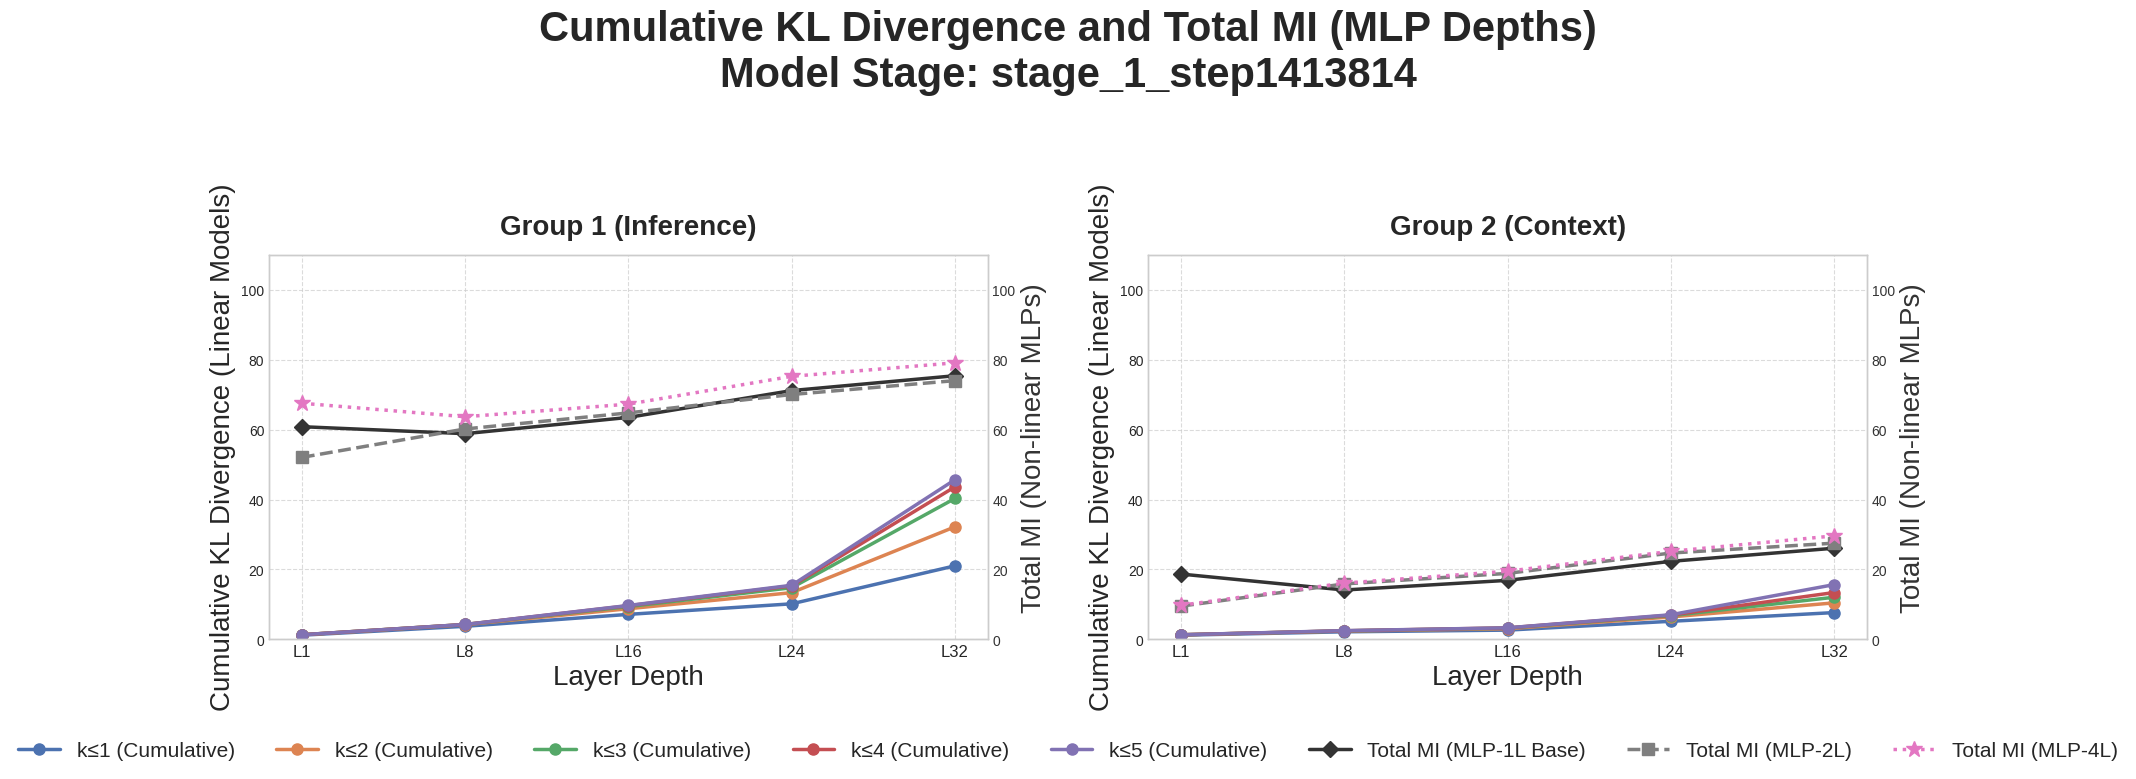

Plotting complete. Saved to 'Result/publish/plot/LLM/olmo/kl_trends/stage_1_step1413814_extended_mlp_depths.png'.


In [11]:
model_stage_name = "stage_1_step1413814" 
FIXED_MAX_KL = 110 
FIXED_MAX_MI = 110 

print("\n" + "="*60)
print(f"Generating Dual-Axis line plots for CUMULATIVE KL and ALL MLP depths... [{model_stage_name}]")
print("="*60)

plt.style.use('seaborn-v0_8-whitegrid')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle(f"Cumulative KL Divergence and Total MI (MLP Depths)\nModel Stage: {model_stage_name}", 
             fontsize=30, fontweight='bold', y=1.05)

x_positions = np.arange(len(plot_layers))
layer_labels = [f"L{l}" for l in plot_layers]

colors = ['#4c72b0', '#dd8452', '#55a868', '#c44e52', '#8172b3']
mlp1_color = '#333333' # Black (Original Total MI)
mlp2_color = '#7f7f7f' # Dark Grey
mlp4_color = '#e377c2' # Pinkish Magenta

def plot_kl_trends_extended(ax_left, data_dict, title):
    cumulative_vals = np.zeros(len(x_positions))
    for k in range(1, 6):
        cumulative_vals += np.array(data_dict[k])
        ax_left.plot(x_positions, cumulative_vals, marker='o', linewidth=2.5, markersize=8,
                     color=colors[k-1], label=f'k≤{k} (Cumulative)')
        
    ax_left.set_xlabel('Layer Depth', fontsize=20)
    ax_left.set_ylabel('Cumulative KL Divergence (Linear Models)', fontsize=20)
    ax_left.set_xticks(x_positions)
    ax_left.set_xticklabels(layer_labels, fontsize=12)
    ax_left.grid(True, linestyle='--', alpha=0.7)

    ax_right = ax_left.twinx()
    
    # 既存の MLP (1層/ベース)
    ax_right.plot(x_positions, data_dict['total_mi'], marker='D', linestyle='-', linewidth=2.5, markersize=8,
                  color=mlp1_color, label='Total MI (MLP-1L Base)')
    # 追加した MLP 2層
    ax_right.plot(x_positions, data_dict['MLP_2L'], marker='s', linestyle='--', linewidth=2.5, markersize=8,
                  color=mlp2_color, label='Total MI (MLP-2L)')
    # 追加した MLP 4層
    ax_right.plot(x_positions, data_dict['MLP_4L'], marker='*', linestyle=':', linewidth=2.5, markersize=12,
                  color=mlp4_color, label='Total MI (MLP-4L)')
    
    ax_right.set_ylabel('Total MI (Non-linear MLPs)', fontsize=20, color=mlp1_color)
    ax_right.tick_params(axis='y', labelcolor=mlp1_color)
    ax_right.grid(False) 
    
    ax_left.set_ylim(0, FIXED_MAX_KL)
    ax_right.set_ylim(0, FIXED_MAX_MI)
    ax_left.set_title(title, fontsize=20, fontweight='bold', pad=15)
    return ax_right

ax1_right = plot_kl_trends_extended(ax1, data_g1, 'Group 1 (Inference)')
ax2_right = plot_kl_trends_extended(ax2, data_g2, 'Group 2 (Context)')

handles_left, labels_left = ax1.get_legend_handles_labels()
handles_right, labels_right = ax1_right.get_legend_handles_labels()

fig.legend(handles_left + handles_right, labels_left + labels_right, 
           loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=8, fontsize=15)

plt.tight_layout(pad=3.0)
fig.subplots_adjust(bottom=0.15)
trend_save_path = f"Result/publish/plot/LLM/olmo/kl_trends/stage_1_step1413814_extended_mlp_depths.png"
os.makedirs(os.path.dirname(trend_save_path), exist_ok=True)
plt.savefig(trend_save_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Plotting complete. Saved to '{trend_save_path}'.")


Generating line plots for Validation MSE trends... [stage_1_step1413814]


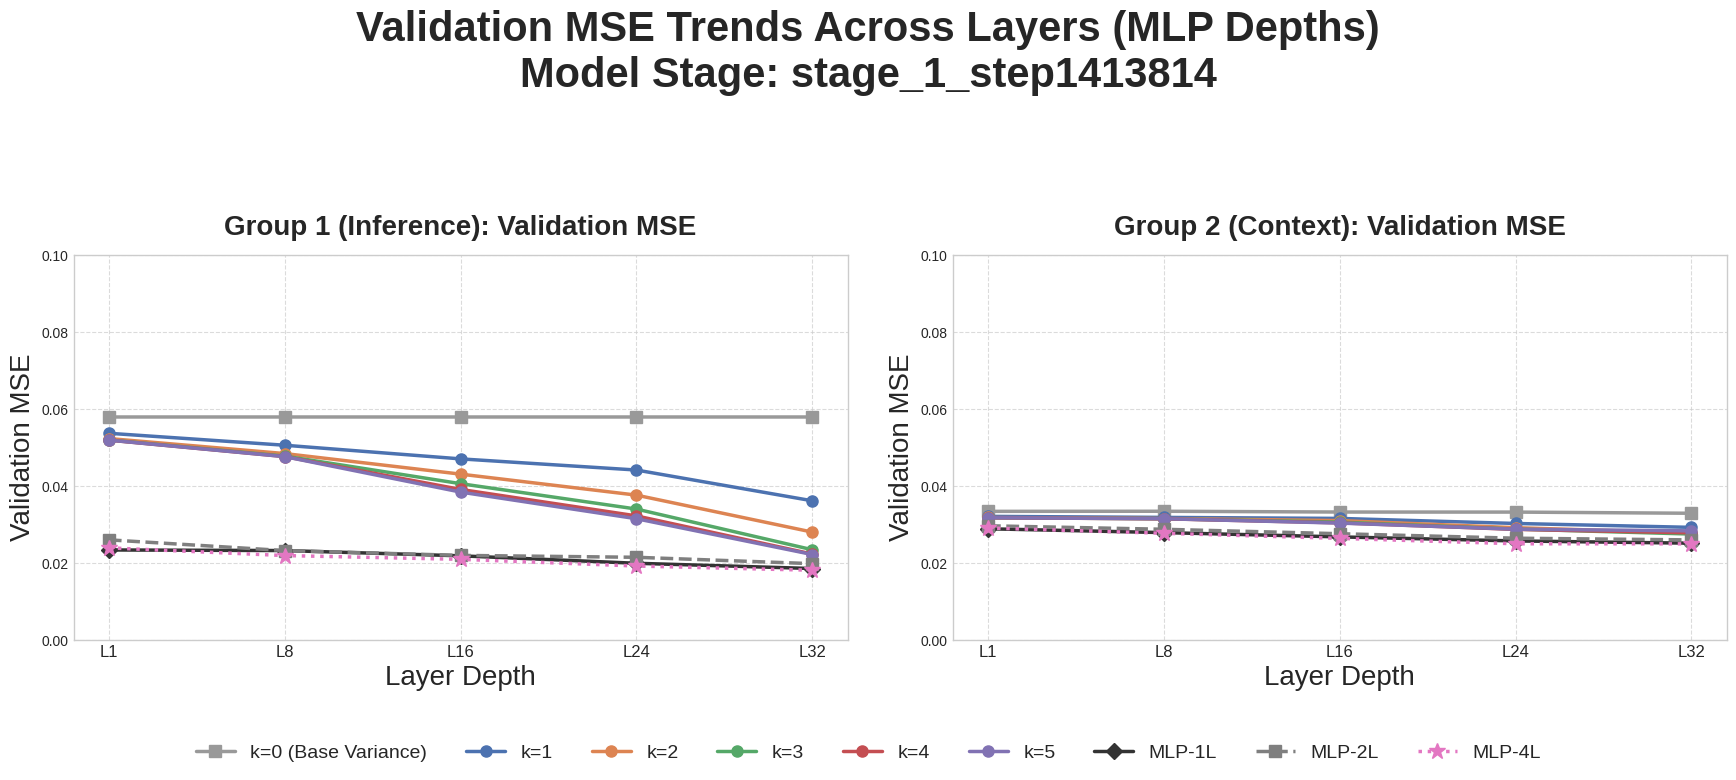

Plotting complete. Saved to 'Result/publish/plot/LLM/olmo/val_mse_trends/stage_1_step1413814_extended_mlp_depths.png'.


In [12]:
print("\n" + "="*60)
print(f"Generating line plots for Validation MSE trends... [{model_stage_name}]")
print("="*60)

FIXED_MAX_MSE = 0.1
fig_mse, (ax1_mse, ax2_mse) = plt.subplots(1, 2, figsize=(18, 7))
fig_mse.suptitle(f"Validation MSE Trends Across Layers (MLP Depths)\nModel Stage: {model_stage_name}", 
                 fontsize=30, fontweight='bold', y=1.05)

color_k0 = '#999999'

def plot_val_mse_trends_extended(ax, data_dict, title):
    ax.plot(x_positions, data_dict['val_mse'][0], marker='s', linewidth=2.5, markersize=8,
            color=color_k0, label='k=0 (Base Variance)')
    
    for k in range(1, 6):
        ax.plot(x_positions, data_dict['val_mse'][k], marker='o', linewidth=2.5, markersize=8,
                color=colors[k-1], label=f'k={k}')
        
    ax.plot(x_positions, data_dict['val_mse']['Total_MI'], marker='D', linestyle='-', linewidth=2.5, markersize=8,
            color=mlp1_color, label='MLP-1L')
    ax.plot(x_positions, data_dict['val_mse']['MLP_2L'], marker='s', linestyle='--', linewidth=2.5, markersize=8,
            color=mlp2_color, label='MLP-2L')
    ax.plot(x_positions, data_dict['val_mse']['MLP_4L'], marker='*', linestyle=':', linewidth=2.5, markersize=12,
            color=mlp4_color, label='MLP-4L')

    ax.set_title(title, fontsize=20, fontweight='bold', pad=15)
    ax.set_xlabel('Layer Depth', fontsize=20)
    ax.set_ylabel('Validation MSE', fontsize=20)
    ax.set_xticks(x_positions)
    ax.set_xticklabels(layer_labels, fontsize=12)
    ax.set_ylim(0, FIXED_MAX_MSE)
    ax.grid(True, linestyle='--', alpha=0.7)

if 'val_mse' in data_g1:
    plot_val_mse_trends_extended(ax1_mse, data_g1, 'Group 1 (Inference): Validation MSE')
if 'val_mse' in data_g2:
    plot_val_mse_trends_extended(ax2_mse, data_g2, 'Group 2 (Context): Validation MSE')

handles, labels = ax1_mse.get_legend_handles_labels()
fig_mse.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=9, fontsize=14)

plt.tight_layout(pad=3.0)
fig_mse.subplots_adjust(bottom=0.15) 
mse_save_path = f"Result/publish/plot/LLM/olmo/val_mse_trends/stage_1_step1413814_extended_mlp_depths.png"
os.makedirs(os.path.dirname(mse_save_path), exist_ok=True)
plt.savefig(mse_save_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Plotting complete. Saved to '{mse_save_path}'.")